In [7]:
from pathlib import Path
import pandas as pd

from matplotlib import pyplot as plt

In [3]:
data = Path('data/diabetes.csv')
df = pd.read_csv(data)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<Axes: xlabel='Pregnancies', ylabel='Glucose'>

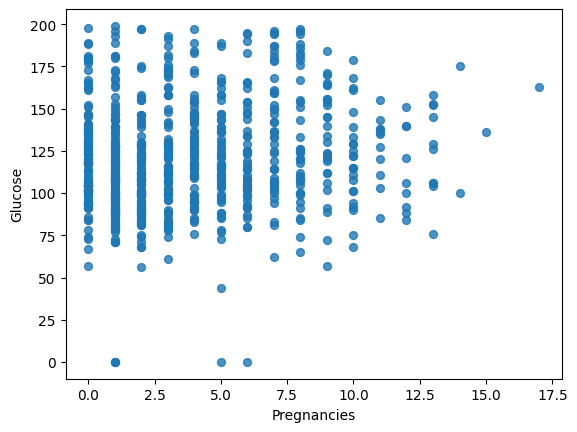

In [23]:

df.plot(kind='scatter', x='Pregnancies', y='Glucose', s=32, alpha=.8)


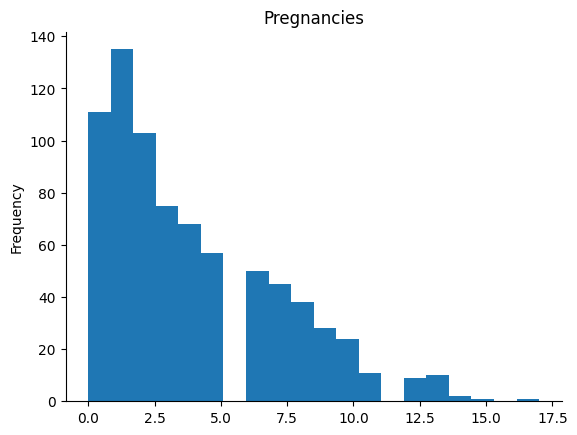

In [22]:

df['Pregnancies'].plot(kind='hist', bins=20, title='Pregnancies')


<Axes: title={'center': 'Glucose'}, ylabel='Frequency'>

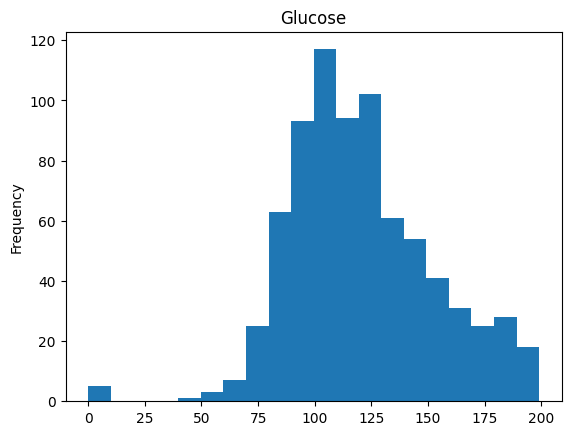

In [20]:

df['Glucose'].plot(kind='hist', bins=20, title='Glucose')


In [11]:
#We need to first read and analyze our data then Create an AI based on it to predict what we want

y = df['Outcome']

#After analyzing and reading our data , we need to create a data set without the outcome

x = df.drop(columns = 'Outcome')

In [12]:
#Now we need to create a dataset based on our data
#A dataset consists of two parts 1-Training Section 2-comparison Section

#We use a library called "sklearn" for machine learning and statistical modeling including classification, regression, clustering and dimensionality reduction.
from sklearn.model_selection import train_test_split

x_train , x_test , y_train , y_test = train_test_split(x,y, random_state = 1 , stratify = y)
#To count our precision, there is a method that reports a number that shows the accuracy of our results

x_train.shape

(576, 8)

In [13]:
#Creating a logistic Regression model

from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(solver = 'lbfgs' , max_iter = 200 , random_state = 1)

classifier

LogisticRegression(max_iter=200, random_state=1)

In [14]:
#Train our model based on data

classifier.fit(x_train , y_train)

LogisticRegression(max_iter=200, random_state=1)

In [15]:
print(f'Training Data Score Is: {classifier.score(x_train , y_train)}')
print(f"Testing Data Score Is: {classifier.score(x_test , y_test)}")

#Using this method we can see our model's accuracy

Training Data Score Is: 0.7829861111111112
Testing Data Score Is: 0.7760416666666666


In [18]:
#Making Predictions and testing our model

prediction = classifier.predict(x_test)
result = pd.DataFrame({"Prediction":prediction , "Actual" : y_test}).reset_index(drop=True)

result.head()

,Prediction,Actual
0,0,0
1,1,1
2,0,0
3,1,1
4,0,0


In [17]:
#50:00
#Classification Report... next